d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Analyzing...


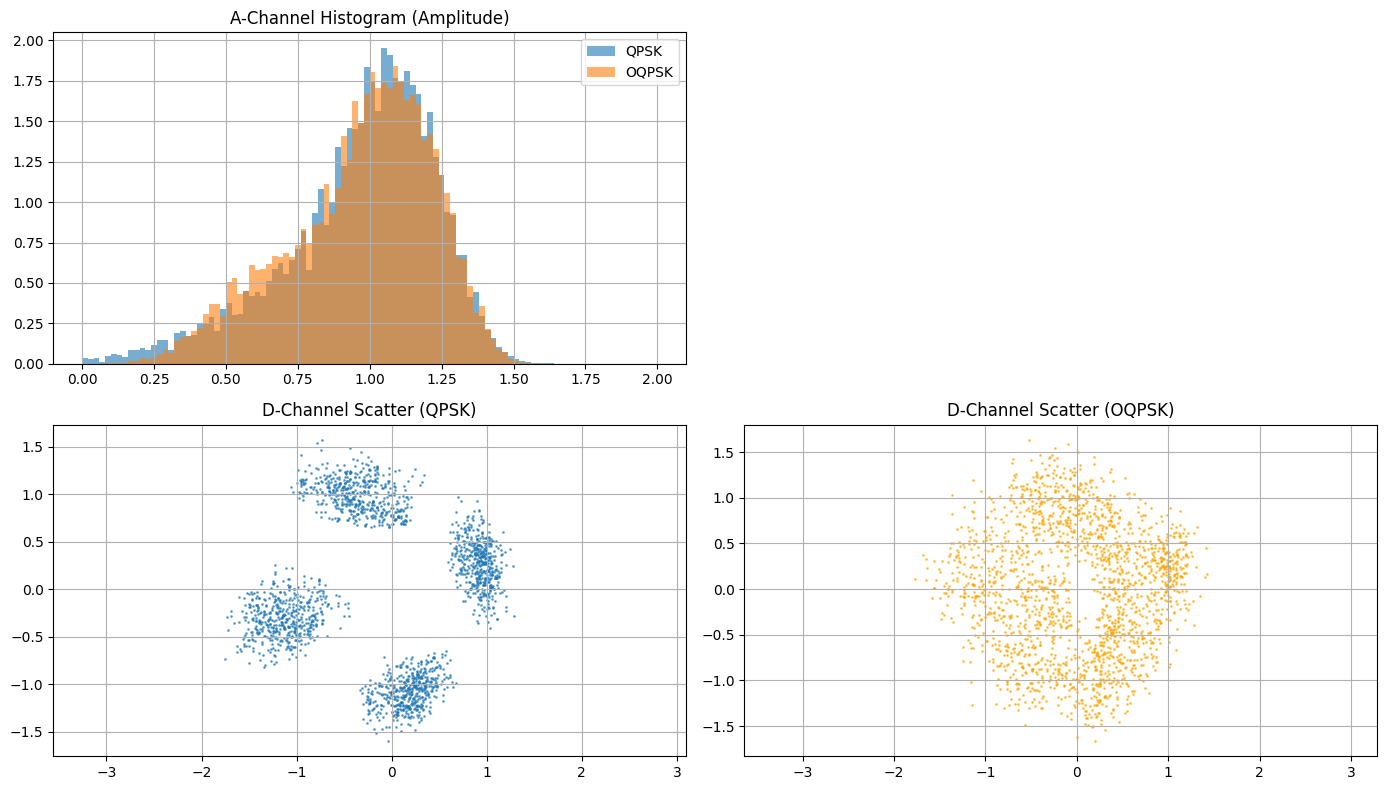

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 你的文件路径
# 请替换为你想要对比的两个文件 (例如 QPSK 和 OQPSK，或者 QPSK 和 8PSK)
FILE_1 = "E:/Project/AMR-Benchmark/L20250425_103838_F6000000000_S400000_B100000_M0_IQ_ID0_nozaoshen_100ksps_QPSK.dat"
FILE_2 = "E:/Project/AMR-Benchmark/L20250425_104306_F6000000000_S400000_B100000_M0_IQ_ID0_nojiazao_100ksps_OQPSK.dat"
LABEL_1 = "QPSK"
LABEL_2 = "OQPSK"

def analyze_ad_channel(file_path, label):
    # 1. 读取数据
    if file_path.endswith('.dat'):
        raw = np.fromfile(file_path, dtype='>i2') # Big Endian
        if len(raw) > 1024: raw = raw[1024:]
    else:
        raw = np.fromfile(file_path, dtype=np.int16)
        
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数 & 归一化
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    # 功率归一化到 1
    iq = iq / np.sqrt(np.mean(np.abs(iq)**2))
    
    # 2. 关键步骤：降采样 (Downsampling)
    # 只有降采样后，D 通道的特征才会显现，否则全是连续的轨迹
    # 步长取 4 (针对你的 100k/25k 信号)
    iq_down = iq[::4]
    
    # --- A 通道 (幅度) ---
    amp = np.abs(iq_down)
    
    # --- D 通道 (差分) ---
    # Diff = S[t] * conj(S[t-1])
    # 也就是相位差: angle(S[t]) - angle(S[t-1])
    diff = iq_down[1:] * np.conj(iq_down[:-1])
    
    return amp, diff

# 运行分析
print("Analyzing...")
amp1, diff1 = analyze_ad_channel(FILE_1, LABEL_1)
amp2, diff2 = analyze_ad_channel(FILE_2, LABEL_2)

# --- 绘图 ---
plt.figure(figsize=(14, 8))

# 1. A 通道直方图对比
plt.subplot(2, 2, 1)
plt.hist(amp1, bins=100, alpha=0.6, label=LABEL_1, density=True, range=(0, 2.0))
plt.hist(amp2, bins=100, alpha=0.6, label=LABEL_2, density=True, range=(0, 2.0))
plt.title("A-Channel Histogram (Amplitude)")
plt.legend()
plt.grid(True)
# 重点看：x=0 附近有没有值？QPSK应该有，OQPSK应该没有。

# 2. D 通道散点图 (极坐标) - File 1
plt.subplot(2, 2, 3)
plt.scatter(diff1.real[:2000], diff1.imag[:2000], s=1, alpha=0.6)
plt.title(f"D-Channel Scatter ({LABEL_1})")
plt.axis('equal')
plt.grid(True)
# 重点看：是 4 个团？还是一个圆环？

# 3. D 通道散点图 (极坐标) - File 2
plt.subplot(2, 2, 4)
plt.scatter(diff2.real[:2000], diff2.imag[:2000], s=1, alpha=0.6, color='orange')
plt.title(f"D-Channel Scatter ({LABEL_2})")
plt.axis('equal')
plt.grid(True)

plt.tight_layout()
plt.show()

Analyzing...


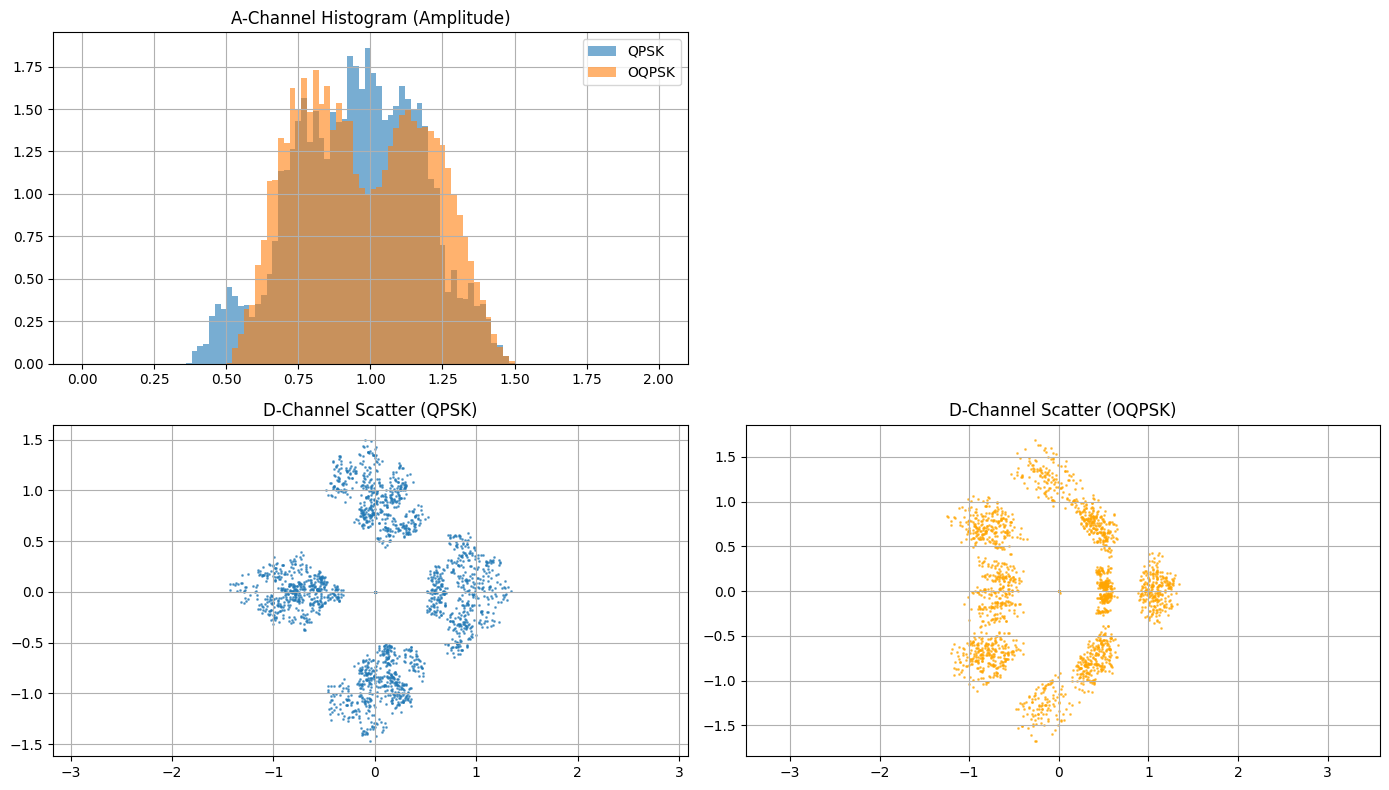

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# 你的文件路径
# 请替换为你想要对比的两个文件 (例如 QPSK 和 OQPSK，或者 QPSK 和 8PSK)
FILE_1 = "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq"
FILE_2 = "E:/Project/AMR-Benchmark/OQPSK-03-24-25-10h54m02s6.iq"
LABEL_1 = "QPSK"
LABEL_2 = "OQPSK"

def analyze_ad_channel(file_path, label):
    # 1. 读取数据
    if file_path.endswith('.dat'):
        raw = np.fromfile(file_path, dtype='>i2') # Big Endian
        if len(raw) > 1024: raw = raw[1024:]
    else:
        raw = np.fromfile(file_path, dtype=np.int16)
        
    if len(raw) % 2 != 0: raw = raw[:-1]
    
    # 转复数 & 归一化
    iq = (raw[::2] + 1j * raw[1::2]).astype(np.complex64)
    # 功率归一化到 1
    iq = iq / np.sqrt(np.mean(np.abs(iq)**2))
    
    # 2. 关键步骤：降采样 (Downsampling)
    # 只有降采样后，D 通道的特征才会显现，否则全是连续的轨迹
    # 步长取 4 (针对你的 100k/25k 信号)
    iq_down = iq[::4]
    
    # --- A 通道 (幅度) ---
    amp = np.abs(iq_down)
    
    # --- D 通道 (差分) ---
    # Diff = S[t] * conj(S[t-1])
    # 也就是相位差: angle(S[t]) - angle(S[t-1])
    diff = iq_down[1:] * np.conj(iq_down[:-1])
    
    return amp, diff

# 运行分析
print("Analyzing...")
amp1, diff1 = analyze_ad_channel(FILE_1, LABEL_1)
amp2, diff2 = analyze_ad_channel(FILE_2, LABEL_2)

# --- 绘图 ---
plt.figure(figsize=(14, 8))

# 1. A 通道直方图对比
plt.subplot(2, 2, 1)
plt.hist(amp1, bins=100, alpha=0.6, label=LABEL_1, density=True, range=(0, 2.0))
plt.hist(amp2, bins=100, alpha=0.6, label=LABEL_2, density=True, range=(0, 2.0))
plt.title("A-Channel Histogram (Amplitude)")
plt.legend()
plt.grid(True)
# 重点看：x=0 附近有没有值？QPSK应该有，OQPSK应该没有。

# 2. D 通道散点图 (极坐标) - File 1
plt.subplot(2, 2, 3)
plt.scatter(diff1.real[:2000], diff1.imag[:2000], s=1, alpha=0.6)
plt.title(f"D-Channel Scatter ({LABEL_1})")
plt.axis('equal')
plt.grid(True)
# 重点看：是 4 个团？还是一个圆环？

# 3. D 通道散点图 (极坐标) - File 2
plt.subplot(2, 2, 4)
plt.scatter(diff2.real[:2000], diff2.imag[:2000], s=1, alpha=0.6, color='orange')
plt.title(f"D-Channel Scatter ({LABEL_2})")
plt.axis('equal')
plt.grid(True)

plt.tight_layout()
plt.show()